# main thing

This notebook imports the pipeline functions from
[`scripts/pipeline_lib.py`](../scripts/pipeline_lib.py).

For Google Colab use
[`pipeline_colab.ipynb`](pipeline_colab.ipynb) instead.


## 1. Setup (import the library and set options)

In [ ]:
# ==== EDIT THESE ====
SLIDE = "slides/tumor_084.tif"   # slide for the single-slide cells (2-6)
MODEL = "plip"                   # foundation model: "plip" or "conch"
RESOLUTION = 0.2                 # spatial-domain clustering resolution
OUT = "outputs"                  # where .zarr stores + preview PNGs go
# ====================

%matplotlib inline
import os, sys
from pathlib import Path
from IPython.display import Image, display

# find the repo root (folder containing scripts/pipeline_lib.py) so the import works
# no matter where the kernel started, then make pipeline_lib importable.
here = Path.cwd()
REPO = next((p for p in [here, *here.parents] if (p / "scripts" / "pipeline_lib.py").exists()), here)
os.chdir(REPO)
sys.path.insert(0, str(REPO / "scripts"))

import pipeline_lib as pl         

cfg = pl.Config(model=MODEL, resolution=RESOLUTION)
slide = Path(SLIDE)

def show(*names):
    """Display the preview PNGs a stage just saved (inline)."""
    for n in names:
        p = Path(OUT) / f"{slide.stem}_{n}.png"
        display(Image(str(p))) if p.exists() else print(f"(no {p.name})")

print(f"pipeline_lib : {pl.__file__}")
print(f"slide        : {slide}   (exists: {slide.exists()})")
print(f"model / amp  : {cfg.model} / {cfg.amp}")
print("ready — run the stage cells below.")

pipeline_lib : /Users/mkoulougousidou/github-projects/lazyslide/scripts/pipeline_lib.py
slide        : slides/tumor_084.tif   (exists: True)
model / amp  : plip / True
ready — run the stage cells below.


## 2. Preprocess (detect tissue, cut into tiles)

opened tumor_084: [86016, 65536]  mpp=0.226
tissue pieces: 2
tiles: 6125


/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/en

[preprocess] saved -> outputs/tumor_084.zarr


/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/en

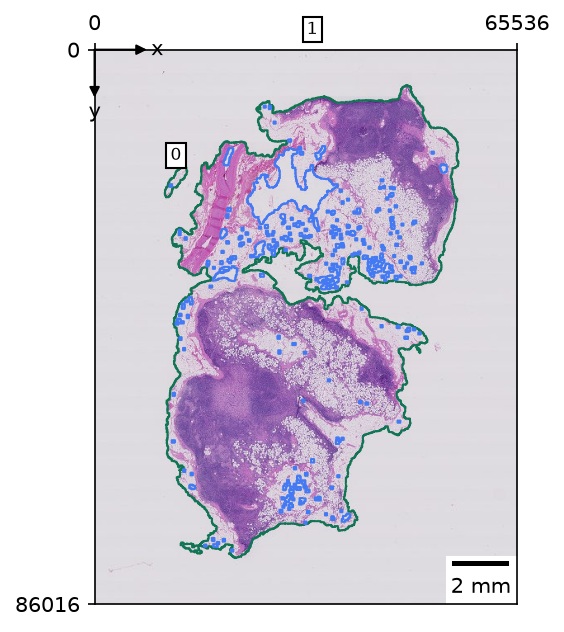

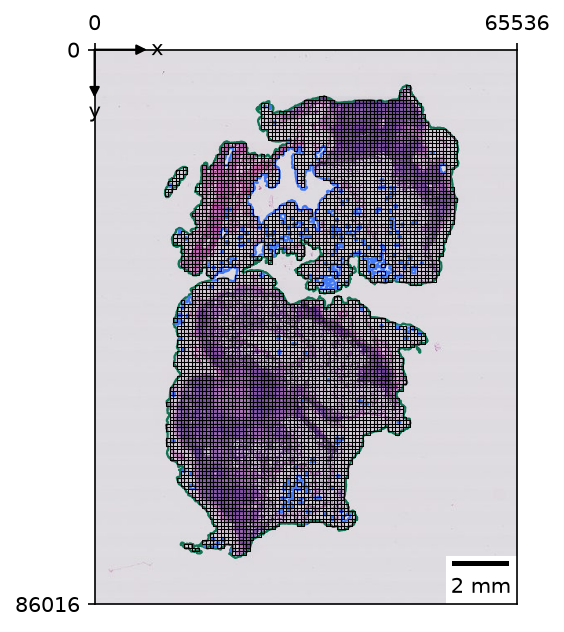

In [16]:
pl.preprocess(slide, cfg, OUT)
show("tissue", "tiles")

## 3. Features (foundation-model features + spatial domains)

tiles: 6125
reusing existing plip features
spatial domains: 5


/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/en

[features] plip features + domains saved


/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/en

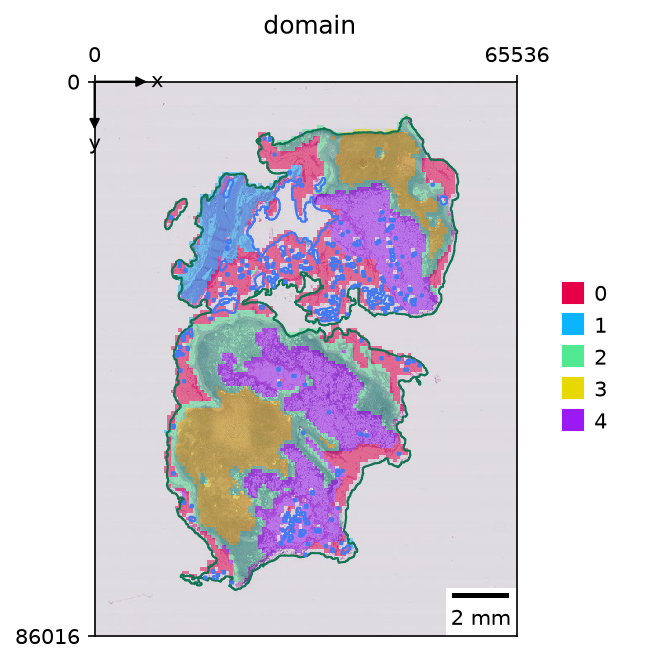

In [17]:
pl.features(slide, cfg, OUT)
show("domains")

## 4. Zero-shot ( training-free tumor score)

zero-shot model: plip


/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/site-packages/lazyslide_models/multimodal/plip.py:27: UserWarning: As from v0.8.2, Normalization will not be applied to image embedding of PLIP model anymore.A `normalize=True` argument is added to the `text_image_similarity` method.If you only use the image embedding for text image similarity, you can safely ignore this warning.
  warnings.warn(
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 47429.62it/s]
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/site-packages/lazyslide/tools/_text_annotate.py:169: UserWarning: As of v0.8.2, the image embedding from image text model is not normalized after feature extraction by default. The normalization is applied here (text_image_similarity),if your features are extracted in previous versions, consider setting normalize=False.
  warnings.warn(msg, stacklevel=find_stack_level())
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/con

[zero_shot] scores saved -> table 'zeroshot'


/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/envs/lazyslide/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/opt/homebrew/Caskroom/miniforge/base/en

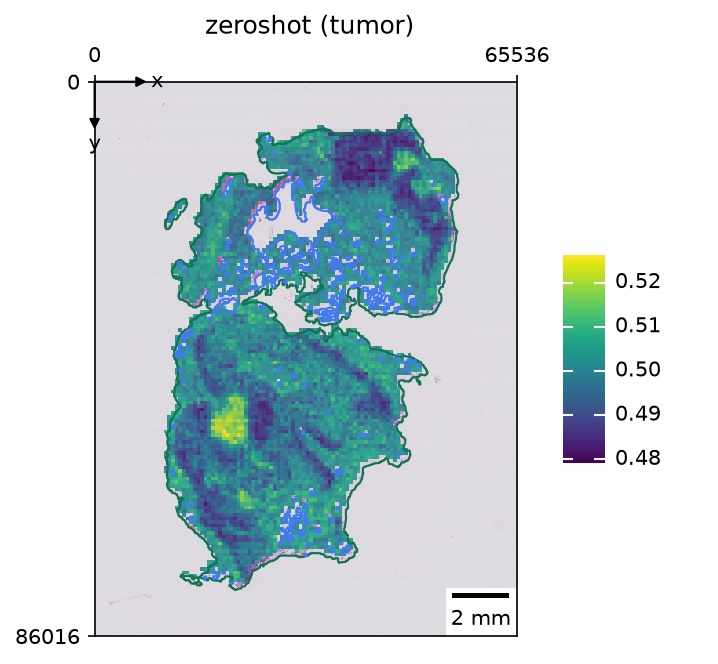

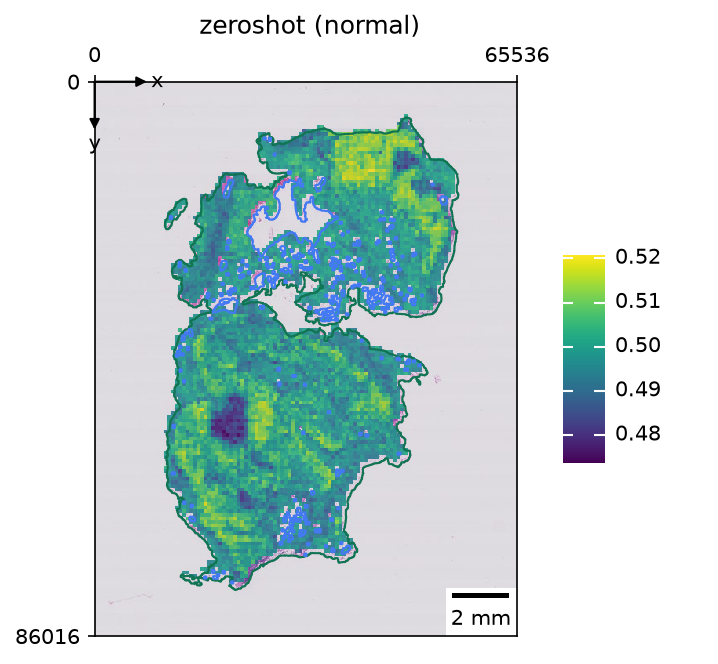

In [7]:
pl.zero_shot(slide, cfg, OUT)
show(*[f"zeroshot_{lab}" for lab in cfg.labels])

## 5. Validate ( ROC-AUC vs ground truth (skips if no annotation))

loaded 54 positive region(s) from tumor_084.xml
mean 'tumor' INSIDE tumor : 0.5157
mean 'tumor' OUTSIDE      : 0.4999
ROC-AUC vs ground truth        : 0.946   (0.5=chance, 1.0=perfect)

ROC-AUC: 0.9463302121782042


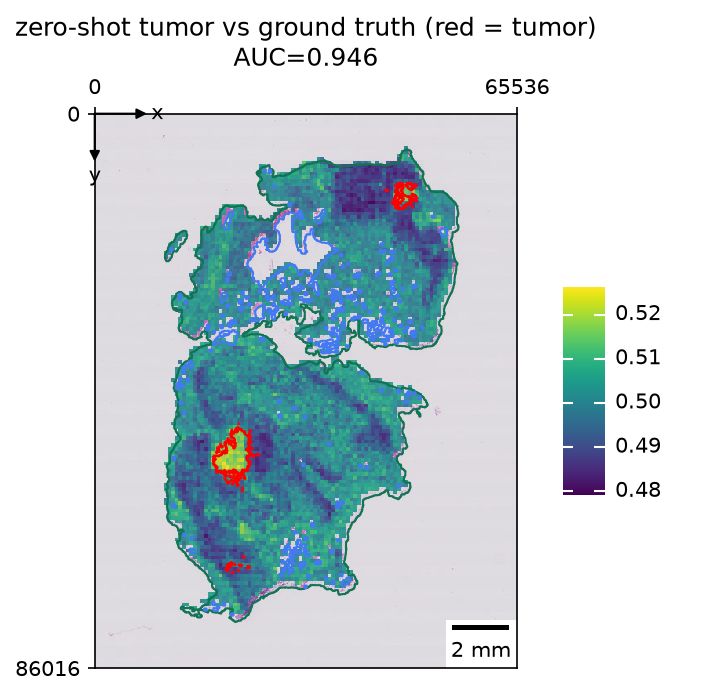

In [8]:
auc = pl.validate(slide, cfg, OUT)
print(f"\nROC-AUC: {auc}" if auc is not None else "\n(validation skipped / undefined)")
show("validation")

## 6. Spatial (neighbour-graph visualization)

[spatial] nodes: 6125  edges: 11485  domains: 5


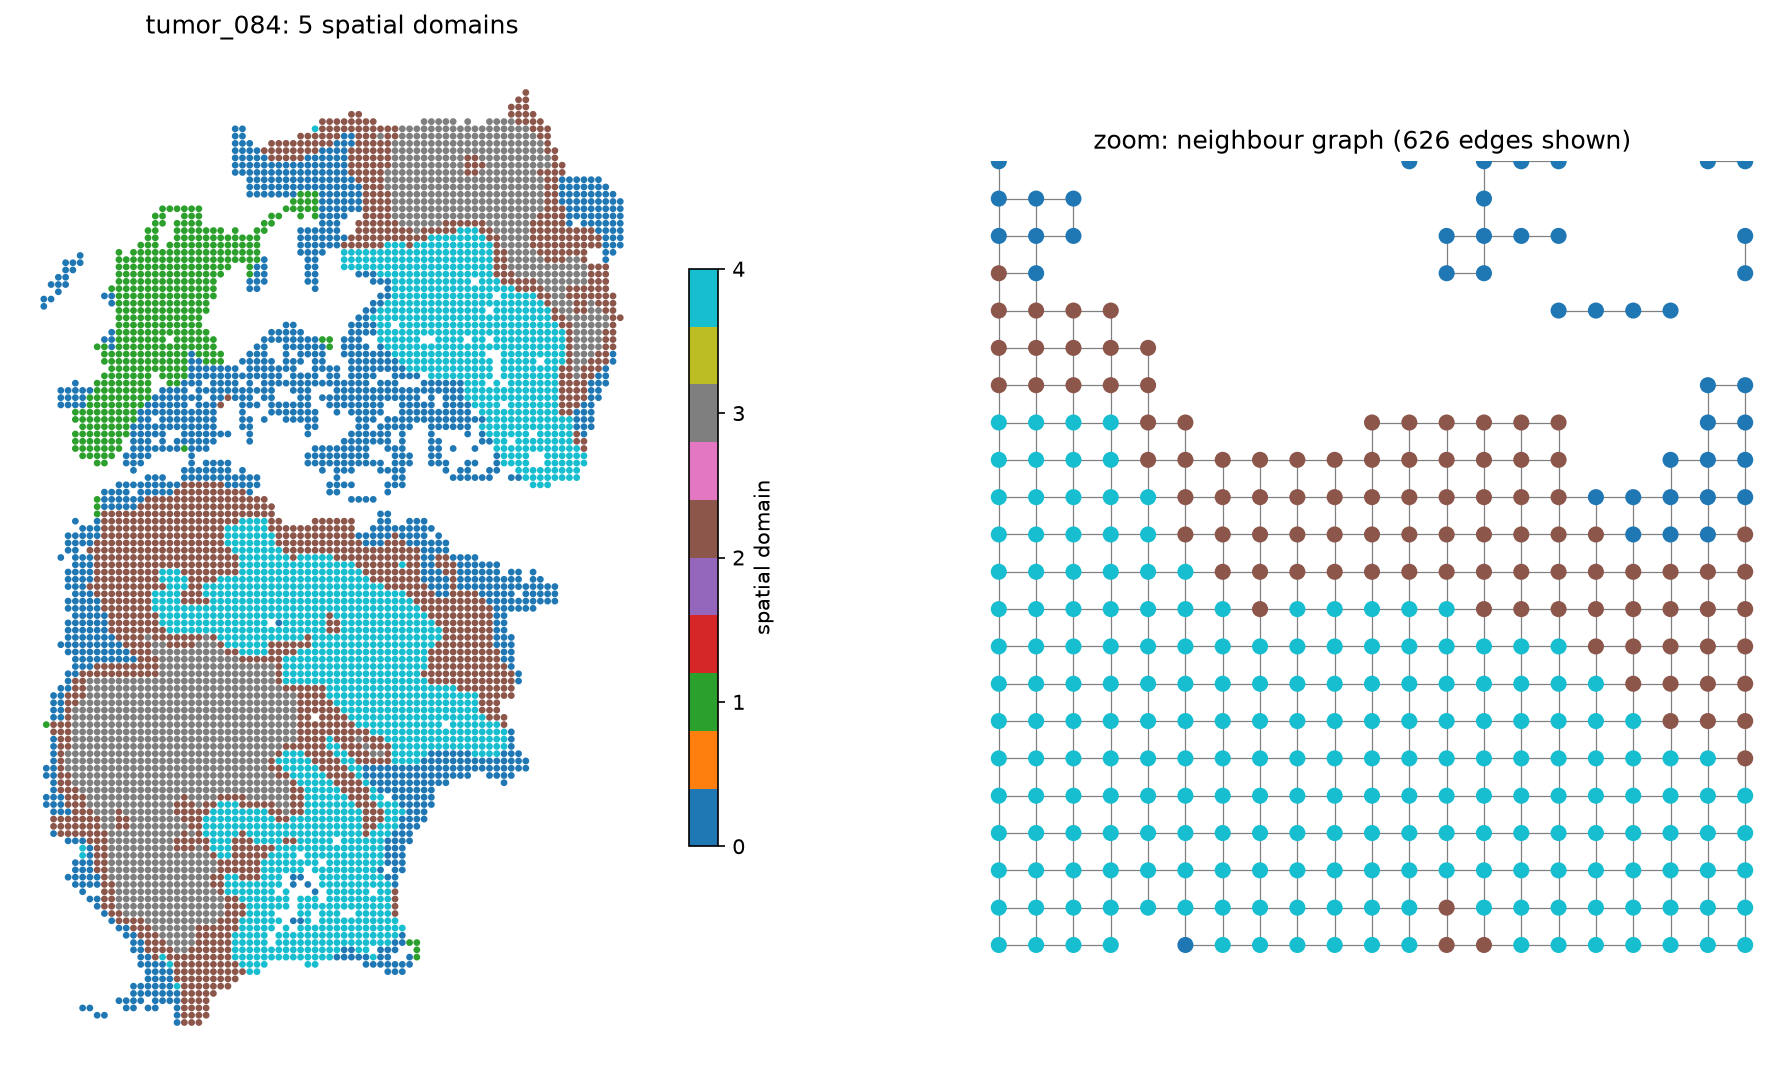

In [9]:
pl.spatial(slide, cfg, OUT)
show("spatial_graph")

## 7. the whole `slides/` folder

`run_cohort` runs the full pipeline on **every** slide in a folder, writes
`outputs/cohort_summary.csv`, and returns a table (one row per slide). One failing
slide doesn't stop the rest; slides whose scores already exist are skipped. 

found 6 slide(s): ['normal_001.tif', 'test_001.tif', 'test_002.tif', 'tumor_001.tif', 'tumor_002.tif', 'tumor_084.tif']
[1/6] normal_001 ...
[validate] no annotation for normal_001 — skipping
[2/6] test_001 ...
loaded 30 positive region(s) from test_001.xml
mean 'tumor' INSIDE tumor : 0.5119
mean 'tumor' OUTSIDE      : 0.5017
ROC-AUC vs ground truth        : 0.882   (0.5=chance, 1.0=perfect)
[3/6] test_002 ...
loaded 23 positive region(s) from test_002.xml
mean 'tumor' INSIDE tumor : 0.5009
mean 'tumor' OUTSIDE      : 0.4881
ROC-AUC vs ground truth        : 0.903   (0.5=chance, 1.0=perfect)
[4/6] tumor_001 ...
loaded 2 positive region(s) from tumor_001.xml
mean 'tumor' INSIDE tumor : 0.4993
mean 'tumor' OUTSIDE      : 0.4940
ROC-AUC vs ground truth        : 0.702   (0.5=chance, 1.0=perfect)
[5/6] tumor_002 ...
loaded 1 positive region(s) from tumor_002.xml
mean 'tumor' INSIDE tumor : 0.5160
mean 'tumor' OUTSIDE      : 0.4970
ROC-AUC vs ground truth        : 0.937   (0.5=chance, 1.0=per

,slide,n_tiles,n_domains,annotation,auc,seconds
0,normal_001,1710,None,None,NaN,0.2
1,test_001,11171,None,test_001.xml,0.881965,1.0
2,test_002,6444,None,test_002.xml,0.903106,0.4
3,tumor_001,6683,None,tumor_001.xml,0.702210,0.4
4,tumor_002,3234,None,tumor_002.xml,0.937384,0.3
5,tumor_084,6125,None,tumor_084.xml,0.946330,0.6


cohort mean AUC: 0.874   (n=5)


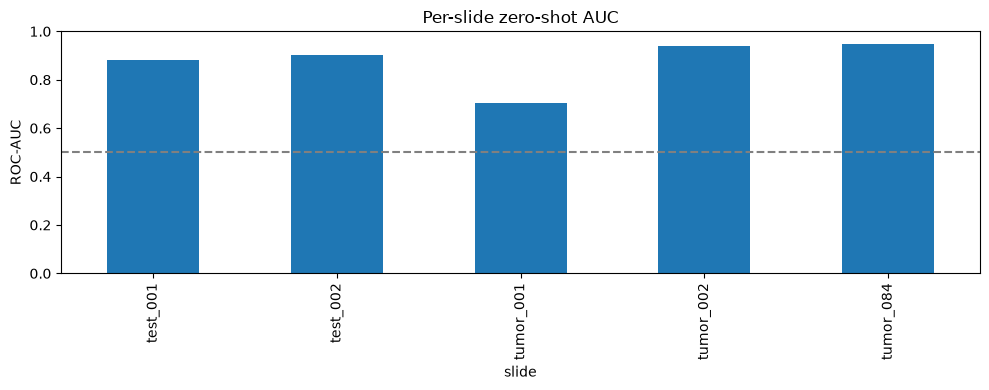

In [18]:
import matplotlib.pyplot as plt

summary = pl.run_cohort("slides", cfg, OUT)
display(summary)

annotated = summary.dropna(subset=["auc"]) if "auc" in summary else summary.iloc[0:0]
if len(annotated):
    print(f"cohort mean AUC: {annotated['auc'].mean():.3f}   (n={len(annotated)})")
    ax = annotated.plot.bar(x="slide", y="auc", legend=False, figsize=(10, 4))
    ax.axhline(0.5, color="grey", ls="--", label="chance")
    ax.set_ylabel("ROC-AUC"); ax.set_ylim(0, 1)
    ax.set_title("Per-slide zero-shot AUC"); plt.tight_layout(); plt.show()